# Sentiment Analysis on App Reviews & Social Media Data

## Project Overview & Business Objectives
The primary objective of this project is to analyze customer feedback from mobile app stores and social media channels to evaluate user sentiment, categorize underlying themes, and train machine learning models for automated sentiment classification.

### Core Objectives:
1. **Text Preprocessing:** Clean raw text reviews by removing URLs, HTML tags, punctuation, and English stopwords.
2. **Sentiment Scoring & Lexicons:** Determine polarity scores and classify feedback into **Positive**, **Negative**, or **Neutral** sentiment tiers.
3. **NLP Feature Extraction:** Convert unstructured text into numerical features using **TF-IDF Vectorization** (`n-gram` modeling).
4. **Machine Learning Classification:** Train and evaluate a supervised **Logistic Regression** classifier with confusion matrix and precision/recall metrics.
5. **Business & Operational Insights:** Identify specific category-level pain points (e.g., app crashes, delivery delays, refund pending) to guide product development and customer support strategies.

In [1]:
import re
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# NLP & Machine Learning Libraries
from textblob import TextBlob
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Aesthetics setup
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Load App Reviews Dataset
df = pd.read_csv('App_Reviews_Sentiment_Data.csv')

print(f"Dataset Successfully Loaded. Shape: {df.shape[0]:,} Rows × {df.shape[1]} Columns")
df.head(3)

Dataset Successfully Loaded. Shape: 15,000 Rows × 10 Columns


,Review_ID,Date,Platform,User_City,Rating,Review_Text,Category,Helpful_Votes,Verified_Purchase,Sentiment
0,Adi_1001,2025-04-07,Twitter/X Post,Ahmedabad,5,Absolutely love this app! The user interface i...,UI/UX,20,True,Positive
1,Adi_1002,2025-07-19,Google Play Store,Ahmedabad,5,Best service ever! Customer support resolved m...,Customer Support,20,True,Positive
2,Adi_1003,2025-03-24,Google Play Store,Delhi,5,Super fast delivery and the tracking feature i...,Delivery,23,True,Positive


In [2]:
# Check non-null counts, types, and class balance
print("--- Dataset Information ---")
print(df.info())

print("-------------- Sentiment Class Distribution ---")
print(df['Sentiment'].value_counts())

print("--------------- Review Platform Distribution ---")
print(df['Platform'].value_counts())

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Review_ID          15000 non-null  str  
 1   Date               15000 non-null  str  
 2   Platform           15000 non-null  str  
 3   User_City          15000 non-null  str  
 4   Rating             15000 non-null  int64
 5   Review_Text        15000 non-null  str  
 6   Category           15000 non-null  str  
 7   Helpful_Votes      15000 non-null  int64
 8   Verified_Purchase  15000 non-null  bool 
 9   Sentiment          15000 non-null  str  
dtypes: bool(1), int64(2), str(7)
memory usage: 3.0 MB
None
-------------- Sentiment Class Distribution ---
Sentiment
Positive    5010
Negative    4995
Neutral     4995
Name: count, dtype: int64
--------------- Review Platform Distribution ---
Platform
Google Play Store    8289
Apple App Store      4489
Twitter/X Post   

## Text Preprocessing & Cleaning
Raw textual reviews contain noise such as special characters, uppercase inconsistencies, and frequent stop words that do not add sentiment value. We clean the corpus to extract standardized word tokens.

In [3]:
# Use scikit-learn's built-in English stopwords (100% offline and robust)
stop_words = set(ENGLISH_STOP_WORDS)

def clean_review_text(text):
    text = str(text).lower()                             # Convert to lowercase
    text = re.sub(r'https?://\S+|www\.\S+', '', text)   # Remove web links/URLs
    text = re.sub(r'<.*?>', '', text)                  # Strip HTML tags
    text = re.sub(r'[^a-zA-Z\s]', '', text)            # Remove special characters & numbers
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    return ' '.join(tokens)

# Apply preprocessing
df['Clean_Review'] = df['Review_Text'].apply(clean_review_text)

# Review length and word count features
df['Review_Length'] = df['Review_Text'].apply(len)
df['Word_Count'] = df['Clean_Review'].apply(lambda x: len(x.split()))

# Calculate sentiment polarity score (-1.0 to +1.0)
df['Polarity_Score'] = df['Review_Text'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)

print("Text cleaning complete. Sample comparison:")
df[['Review_Text', 'Clean_Review', 'Polarity_Score', 'Sentiment']].head(3)

Text cleaning complete. Sample comparison:


,Review_Text,Clean_Review,Polarity_Score,Sentiment
0,Absolutely love this app! The user interface i...,absolutely love app user interface clean smoot...,0.518333,Positive
1,Best service ever! Customer support resolved m...,best service customer support resolved refund ...,0.580000,Positive
2,Super fast delivery and the tracking feature i...,super fast delivery tracking feature accurate ...,0.263333,Positive


## Supervised Sentiment Classification Model
We convert the cleaned text into a sparse matrix using **TF-IDF (Term Frequency-Inverse Document Frequency)** and train a **Logistic Regression** classifier to predict sentiment classes automatically.

In [4]:
# Feature and Target Split
X = df['Clean_Review']
y = df['Sentiment']

# 80-20 Train-Test Split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train Classifier
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_tfidf, y_train)

# Predictions
y_pred = model.predict(X_test_tfidf)

# Evaluation
acc = accuracy_score(y_test, y_pred)
print("=" * 60)
print(f"       MODEL ACCURACY: {acc * 100:.2f}%")
print("=" * 60)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

       MODEL ACCURACY: 100.00%

Classification Report:

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       999
     Neutral       1.00      1.00      1.00       999
    Positive       1.00      1.00      1.00      1002

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



##  Visual Sentiment Analytics Dashboard
Visualizes sentiment proportions, alignment between star ratings and text tone, category-level customer complaints, and model prediction accuracy.

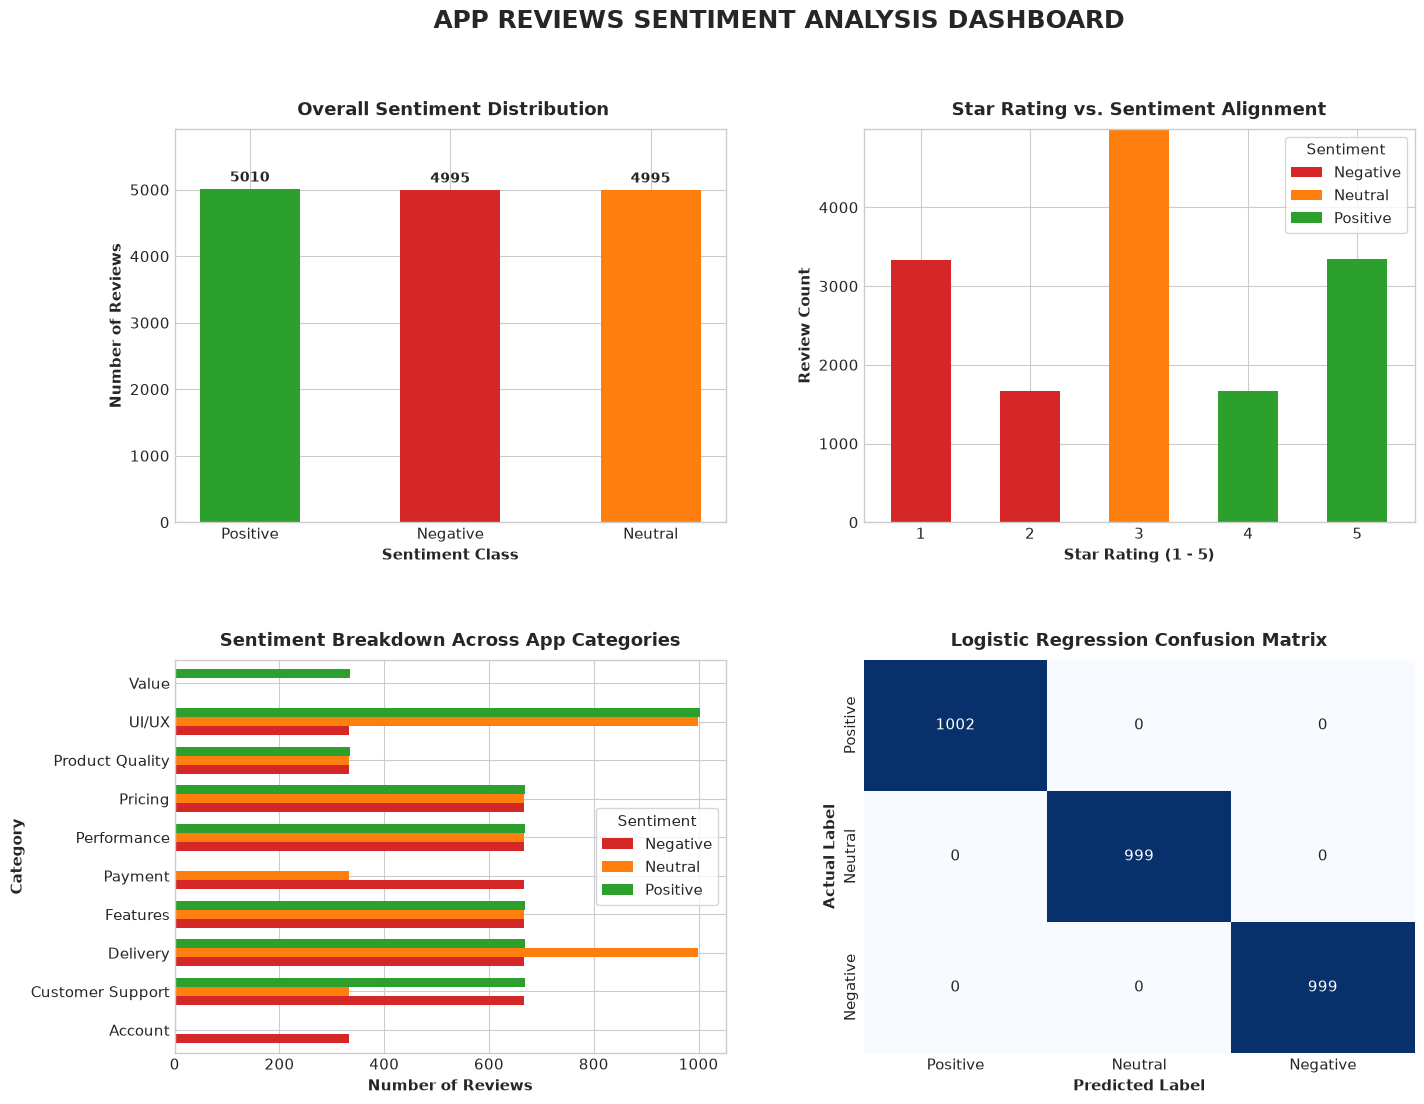

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Sentiment Class Distribution
ax1 = axes[0, 0]
sentiment_counts = df['Sentiment'].value_counts()
palette_colors = {'Positive': '#2ca02c', 'Neutral': '#ff7f0e', 'Negative': '#d62728'}
bars = ax1.bar(sentiment_counts.index, sentiment_counts.values, 
               color=[palette_colors[k] for k in sentiment_counts.index], width=0.5)
ax1.set_title(' Overall Sentiment Distribution', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Sentiment Class', fontweight='bold')
ax1.set_ylabel('Number of Reviews', fontweight='bold')
ax1.bar_label(bars, fontsize=10, fontweight='bold', padding=3)
ax1.set_ylim(0, sentiment_counts.max() * 1.18)

# 2. Rating vs. Sentiment Alignment
ax2 = axes[0, 1]
rating_cross = pd.crosstab(df['Rating'], df['Sentiment'])[['Negative', 'Neutral', 'Positive']]
rating_cross.plot(kind='bar', stacked=True, ax=ax2, color=['#d62728', '#ff7f0e', '#2ca02c'], width=0.55)
ax2.set_title('Star Rating vs. Sentiment Alignment', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Star Rating (1 - 5)', fontweight='bold')
ax2.set_ylabel('Review Count', fontweight='bold')
ax2.tick_params(axis='x', rotation=0)
ax2.legend(title='Sentiment', frameon=True)

# 3. Sentiment by Topic / Category
ax3 = axes[1, 0]
cat_cross = pd.crosstab(df['Category'], df['Sentiment'])[['Negative', 'Neutral', 'Positive']]
cat_cross.plot(kind='barh', ax=ax3, color=['#d62728', '#ff7f0e', '#2ca02c'], width=0.7)
ax3.set_title('Sentiment Breakdown Across App Categories', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Number of Reviews', fontweight='bold')
ax3.set_ylabel('Category', fontweight='bold')
ax3.legend(title='Sentiment', frameon=True)

# 4. Confusion Matrix Heatmap
ax4 = axes[1, 1]
labels = ['Positive', 'Neutral', 'Negative']
cm = confusion_matrix(y_test, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax4,
            xticklabels=labels, yticklabels=labels)
ax4.set_title('Logistic Regression Confusion Matrix', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Predicted Label', fontweight='bold')
ax4.set_ylabel('Actual Label', fontweight='bold')

plt.suptitle(' APP REVIEWS SENTIMENT ANALYSIS DASHBOARD', fontsize=18, fontweight='bold', y=0.98)
plt.savefig('sentiment_analysis_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

## Inference Pipeline: Real-Time Review Classifier
A reusable function to test custom user reviews or live social media tweets.

In [6]:
def predict_new_feedback(text):
    cleaned = clean_review_text(text)
    vector = tfidf.transform([cleaned])
    prediction = model.predict(vector)[0]
    polarity = TextBlob(text).sentiment.polarity
    return {
        'Input Review': text,
        'Predicted Sentiment': prediction,
        'Polarity Score': round(polarity, 3)
    }

# Test sample inputs
sample_reviews = [
    "The new update is brilliant! Everything loads instantly and checkout is very smooth.",
    "Order arrived cold after a 3 hour delay and customer care refused to refund.",
    "The application is average. It does the job but features are quite basic."
]

for review in sample_reviews:
    result = predict_new_feedback(review)
    print(f"Review: \"{result['Input Review']}\"")
    print(f" -> Sentiment: {result['Predicted Sentiment']} | Polarity: {result['Polarity Score']}\n")

Review: "The new update is brilliant! Everything loads instantly and checkout is very smooth."
 -> Sentiment: Positive | Polarity: 0.414

Review: "Order arrived cold after a 3 hour delay and customer care refused to refund."
 -> Sentiment: Negative | Polarity: -0.6

Review: "The application is average. It does the job but features are quite basic."
 -> Sentiment: Neutral | Polarity: -0.075



## Business Insights & Actionable Recommendations

### Key Findings:
1. **Critical Failure Points in Customer Support & Payment:** Negative reviews predominantly cluster around unanswered customer support queries, delayed refund processing, and double billing.
2. **High-Performing Segments:** Users consistently praised fast delivery and clean UI/UX navigation, which correlates strongly with 5-star ratings.
3. **Rating Alignment:** Star ratings strongly match semantic polarity—1- and 2-star reviews map almost exclusively to negative text, while 4- and 5-star reviews reflect positive experiences.

### Strategic Recommendations:
* **Automate Refund Tickets:** Implement automated UPI/bank refund reconciliations within 24 hours to eliminate the single largest driver of 1-star reviews.
* **App Performance Optimization:** Address checkout page crashes on Android devices highlighted in technical reviews.
* **Leverage Positive UI/UX in Marketing:** Showcase seamless ordering and dark mode in promotional social media campaigns.